# V16 — Feature-wise normalized reconstruction-error experiment (XSS test)

Reuses the trained V15 ensemble. The unknown test classes are **Web Attack - XSS**, **FTP-Patator**, and **DoS Slowhttptest**; Botnet is excluded.

**Run the XSS version of Notebook 01 first** to regenerate `data/processed/unknown_detection/balanced_unknown_test.csv`. This notebook validates the expected labels and fails rather than silently evaluating stale Botnet data.

Feature-error normalization uses BENIGN training flows only; thresholds use BENIGN validation flows only. Prior experimentation used held-out data, so use a fresh test set for unbiased final claims.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from tensorflow import keras
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay)

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks': PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path: sys.path.insert(0, str(PROJECT_ROOT))
from autoencoder_v15_common import validate_frame, transform, reconstruction_mse

DATA_DIR = PROJECT_ROOT / 'data' / 'processed' / 'unknown_detection'
MODEL_DIR = PROJECT_ROOT / 'saved-models' / 'autoencoder_v15'
RESULTS_DIR = PROJECT_ROOT / 'outputs' / 'results' / 'autoencoder_v16'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
TRAIN_SAMPLE = 100000  # BENIGN training reference sample, adjustable for memory
TARGET_FPR = 0.03
BATCH_SIZE = 2048
selection = json.loads((MODEL_DIR / 'autoencoder_v15_selection.json').read_text())
prep = joblib.load(MODEL_DIR / 'autoencoder_v15_preprocessing.joblib')
models = [keras.models.load_model(MODEL_DIR / name) for name in selection['model_files']]
print('Models loaded:', len(models))


Models loaded: 3


In [2]:
def load_scaled(path, benign_only=False, sample=None):
    frame = pd.read_csv(path, low_memory=False)
    if sample is not None and len(frame) > sample:
        frame = frame.sample(n=sample, random_state=SEED)
    frame, numeric = validate_frame(frame, path.name, benign_only=benign_only)
    return frame.reset_index(drop=True), transform(numeric, prep)

def per_feature_errors(X, batch_size=BATCH_SIZE):
    result = np.empty(X.shape, dtype=np.float32)
    for start in range(0, len(X), batch_size):
        stop = min(start + batch_size, len(X))
        batch = X[start:stop]
        total = np.zeros(batch.shape, dtype=np.float64)
        for model in models:
            prediction = model.predict(batch, batch_size=batch_size, verbose=0)
            total += (batch.astype(np.float64) - prediction.astype(np.float64)) ** 2
        result[start:stop] = (total / len(models)).astype(np.float32)
    return result

train_df, x_train = load_scaled(DATA_DIR / 'normal_train.csv', benign_only=True, sample=TRAIN_SAMPLE)
val_df, x_val = load_scaled(DATA_DIR / 'normal_validation.csv', benign_only=True)
test_df, x_test = load_scaled(DATA_DIR / 'balanced_unknown_test.csv')
train_err = per_feature_errors(x_train)
val_err = per_feature_errors(x_val)
test_err = per_feature_errors(x_test)
feature_names = list(prep['columns'])
assert train_err.shape[1] == val_err.shape[1] == test_err.shape[1] == len(feature_names)
print('Reference/validation/test shapes:', train_err.shape, val_err.shape, test_err.shape)
print(test_df['Label'].value_counts())


Reference/validation/test shapes: (100000, 73) (214848, 73) (11460, 73)
Label
BENIGN              5730
FTP-Patator         3972
DoS Slowhttptest    1740
Web Attack - XSS      18
Name: count, dtype: int64


## Normalization and scoring

Use `log1p` on squared errors, then robustly standardize each feature using the **BENIGN training reference** median and IQR. Clip negative standardized values to zero, so the aggregate represents unusually high reconstruction errors. Equal weighting is fixed before looking at attack results; no Web Attack - XSS-based feature selection.

In [3]:
log_train = np.log1p(train_err.astype(np.float64))
reference_median = np.median(log_train, axis=0)
q25, q75 = np.quantile(log_train, [0.25, 0.75], axis=0)
reference_iqr = q75 - q25
# Floor avoids exploding normalized errors for nearly constant features.
scale_floor = max(float(np.median(reference_iqr[reference_iqr > 1e-9])) * 0.05, 1e-5) if np.any(reference_iqr > 1e-9) else 1e-5
reference_scale = np.maximum(reference_iqr, scale_floor)

def normalized_feature_scores(errors):
    z = (np.log1p(errors.astype(np.float64)) - reference_median) / reference_scale
    return np.clip(z, 0, 20)

def score_methods(errors):
    normalized = normalized_feature_scores(errors)
    return {
        'V15 mean MSE': errors.mean(axis=1),
        'V16 normalized mean': normalized.mean(axis=1),
        'V16 normalized top-5': np.partition(normalized, -min(5, normalized.shape[1]), axis=1)[:, -min(5, normalized.shape[1]):].mean(axis=1),
    }

val_scores = score_methods(val_err)
test_scores = score_methods(test_err)
thresholds = {name: float(np.quantile(values, 1 - TARGET_FPR)) for name, values in val_scores.items()}
print('BENIGN-validation thresholds:', thresholds)
joblib.dump({'features': feature_names, 'median': reference_median,
             'scale': reference_scale, 'scale_floor': scale_floor,
             'thresholds': thresholds, 'target_fpr': TARGET_FPR,
             'train_sample': TRAIN_SAMPLE}, RESULTS_DIR / 'v16_score_calibration.joblib')


BENIGN-validation thresholds: {'V15 mean MSE': 0.017142509855329977, 'V16 normalized mean': 6.824904065743803, 'V16 normalized top-5': 20.0}


['C:\\Users\\saaral\\Desktop\\gc\\pattern recog\\project\\]code\\Hybrid-Network-Intrusion-Detection\\outputs\\results\\autoencoder_v16\\v16_score_calibration.joblib']

,Method,Threshold,Validation FPR,Test FPR,Accuracy,Precision,Recall,F1,ROC-AUC,TN,FP,FN,TP,Web Attack - XSS recall,FTP-Patator recall,DoS Slowhttptest recall
0,V15 mean MSE,0.0171,0.03,0.0328,0.9682,0.9673,0.9693,0.9683,0.9769,5542,188,176,5554,1.0000,0.9962,0.9075
1,V16 normalized mean,6.8249,0.03,0.0319,0.9688,0.9681,0.9695,0.9688,0.9781,5547,183,175,5555,0.9444,0.9960,0.9092
2,V16 normalized top-5,20.0000,0.00,0.0000,0.5000,0.0000,0.0000,0.0000,0.9655,5730,0,5730,0,0.0000,0.0000,0.0000


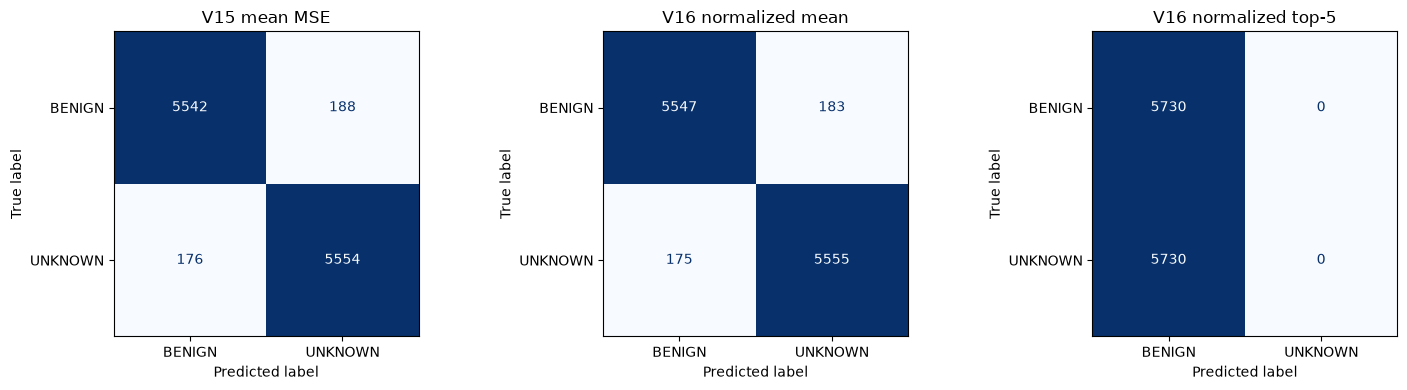

In [4]:
labels = test_df['Label'].astype(str).str.strip().to_numpy()
required_labels = {'BENIGN', 'Web Attack - XSS', 'FTP-Patator', 'DoS Slowhttptest'}
missing_labels = required_labels - set(labels)
if missing_labels:
    raise ValueError(f'Missing expected labels in balanced_unknown_test.csv: {sorted(missing_labels)}. Regenerate CSVs with the XSS version of Notebook 01. Available labels: {sorted(set(labels))}')
if any('Attempted' in label for label in set(labels)):
    raise ValueError('Attempted attack labels detected in testing; rerun Notebook 01 relabeling.')
y_true = (labels != 'BENIGN').astype(int)
rows = []
for name, scores in test_scores.items():
    threshold = thresholds[name]
    y_pred = (scores > threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    row = {'Method': name, 'Threshold': threshold,
           'Validation FPR': float(np.mean(val_scores[name] > threshold)),
           'Test FPR': float(fp / (fp + tn)) if fp + tn else np.nan,
           'Accuracy': accuracy_score(y_true, y_pred),
           'Precision': precision_score(y_true, y_pred, zero_division=0),
           'Recall': recall_score(y_true, y_pred, zero_division=0),
           'F1': f1_score(y_true, y_pred, zero_division=0),
           'ROC-AUC': roc_auc_score(y_true, scores),
           'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp}
    for attack in ['Web Attack - XSS', 'FTP-Patator', 'DoS Slowhttptest']:
        mask = labels == attack
        row[f'{attack} recall'] = float(np.mean(y_pred[mask])) if mask.any() else np.nan
    rows.append(row)
summary = pd.DataFrame(rows)
display(summary.round(4))
summary.to_csv(RESULTS_DIR / 'v16_method_comparison.csv', index=False)

fig, axes = plt.subplots(1, len(test_scores), figsize=(5 * len(test_scores), 4))
for ax, (name, scores) in zip(np.atleast_1d(axes), test_scores.items()):
    predictions = (scores > thresholds[name]).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_true, predictions, labels=[0,1]),
                           display_labels=['BENIGN','UNKNOWN']).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'v16_confusion_matrices.png', dpi=160)
plt.show()


Attack,DoS Slowhttptest,FTP-Patator,Web Attack - XSS
Method,,,
V15 mean MSE,0.9870,0.9724,0.9760
V16 normalized mean,0.9905,0.9727,0.9743
V16 normalized top-5,0.9652,0.9656,0.9656


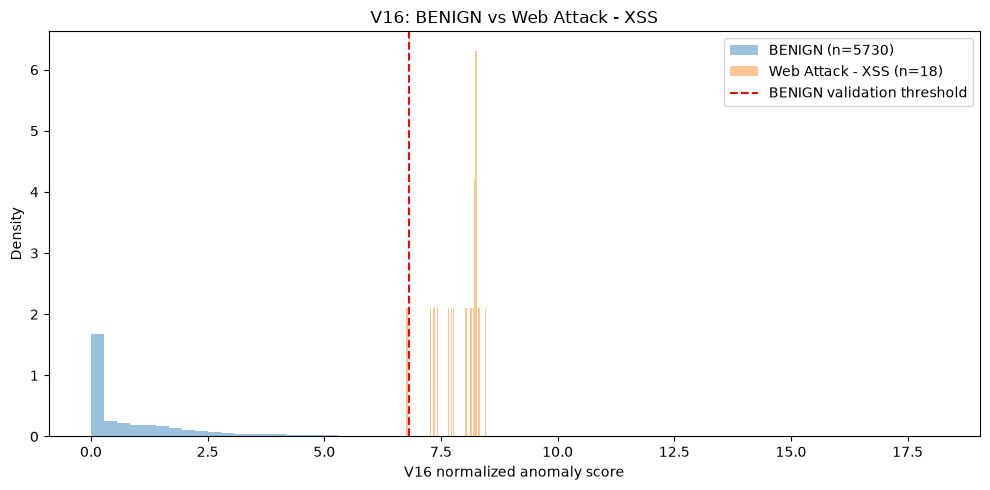

Saved outputs in: C:\Users\saaral\Desktop\gc\pattern recog\project\]code\Hybrid-Network-Intrusion-Detection\outputs\results\autoencoder_v16
Research caveat: same test records motivated this experiment; use a fresh untouched test for final claims.


In [5]:
# Compare class-wise ROC-AUC without selecting weights or thresholds using attack labels.
auc_rows = []
for attack in ['Web Attack - XSS', 'FTP-Patator', 'DoS Slowhttptest']:
    mask = np.isin(labels, ['BENIGN', attack])
    if not (labels == attack).any(): continue
    truth = (labels[mask] == attack).astype(int)
    for method, values in test_scores.items():
        auc_rows.append({'Attack': attack, 'Method': method,
                         'ROC-AUC': roc_auc_score(truth, values[mask])})
auc_table = pd.DataFrame(auc_rows)
display(auc_table.pivot(index='Method', columns='Attack', values='ROC-AUC').round(4))
auc_table.to_csv(RESULTS_DIR / 'v16_classwise_auc.csv', index=False)

fig, ax = plt.subplots(figsize=(10, 5))
for label in ['BENIGN', 'Web Attack - XSS']:
    mask = labels == label
    values = test_scores['V16 normalized mean'][mask]
    if mask.any():
        ax.hist(values, bins=65, density=True, alpha=0.45, label=f'{label} (n={mask.sum()})')
ax.axvline(thresholds['V16 normalized mean'], color='red', linestyle='--', label='BENIGN validation threshold')
ax.set(xlabel='V16 normalized anomaly score', ylabel='Density', title='V16: BENIGN vs Web Attack - XSS')
ax.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'v16_xss_histogram.png', dpi=160)
plt.show()
print('Saved outputs in:', RESULTS_DIR)
print('Research caveat: same test records motivated this experiment; use a fresh untouched test for final claims.')


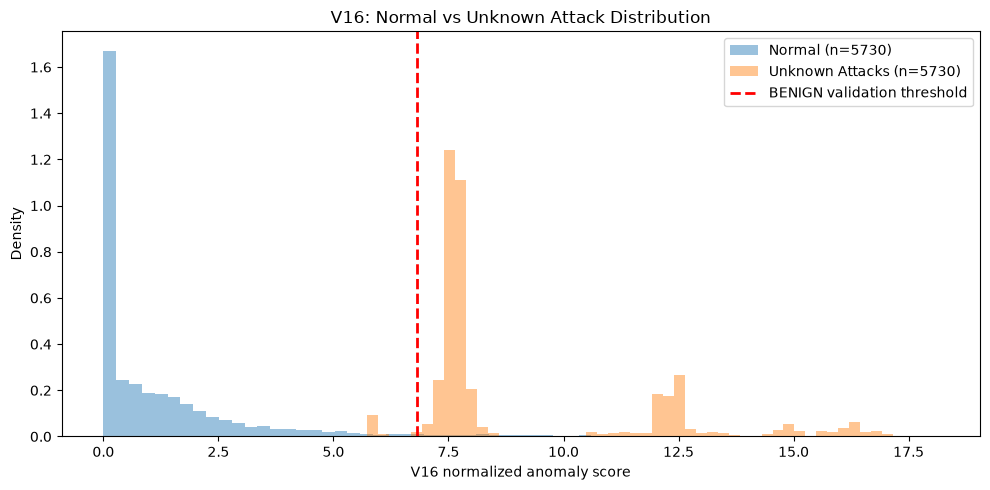

Normal samples: 5730
Unknown attack samples: 5730
Saved outputs in: C:\Users\saaral\Desktop\gc\pattern recog\project\]code\Hybrid-Network-Intrusion-Detection\outputs\results\autoencoder_v16


In [6]:

# ============================================================
# V16: BENIGN vs UNKNOWN ATTACKS
# ============================================================

unknown_classes = [
    'Web Attack - XSS',
    'FTP-Patator',
    'DoS Slowhttptest'
]

# Normal traffic
normal_mask = labels == 'BENIGN'

# Combine all unknown attack classes
unknown_mask = np.isin(labels, unknown_classes)

# Get anomaly scores
normal_scores = test_scores['V16 normalized mean'][normal_mask]
unknown_scores = test_scores['V16 normalized mean'][unknown_mask]

# Plot histogram
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    normal_scores,
    bins=65,
    density=True,
    alpha=0.45,
    label=f'Normal (n={normal_mask.sum()})'
)

ax.hist(
    unknown_scores,
    bins=65,
    density=True,
    alpha=0.45,
    label=f'Unknown Attacks (n={unknown_mask.sum()})'
)

# Threshold from BENIGN validation data
ax.axvline(
    thresholds['V16 normalized mean'],
    color='red',
    linestyle='--',
    linewidth=2,
    label='BENIGN validation threshold'
)

ax.set(
    xlabel='V16 normalized anomaly score',
    ylabel='Density',
    title='V16: Normal vs Unknown Attack Distribution'
)

ax.legend()
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / 'v16_normal_vs_unknown_histogram.png',
    dpi=160
)

plt.show()

print('Normal samples:', normal_mask.sum())
print('Unknown attack samples:', unknown_mask.sum())
print('Saved outputs in:', RESULTS_DIR)
